# Publication-Quality Plots (Halo Split)

Combined feature-importance figures for the revised submission, using the
train/test split by halo ID (`GrNr`) rather than by subhalo/galaxy ID. Each
figure is a 2 (rows: Random Forest, XGBoost) × 3 (columns: All Centrals,
Low-Mass Satellites, High-Mass Satellites) grid of feature-importance bar
charts with inset pie charts. The combined-satellite panels have been removed
per the reviewer request.

- **Classification** results (halo split) are saved to `../pubplots/classification_six_panel_halosplit.pdf`
- **Regression** results now also use the halo-based split and are saved to `../pubplots/regression_six_panel_halosplit.pdf`

Run this notebook from the `pubplots/` directory (paths are relative).

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

## Data locations & style

In [10]:
# Output directories of the individual model runs (relative to pubplots/)
RF_CLF = "../classification_revised/rf_classification_annuli/rf_classification_outputs"
XG_CLF = "../classification_revised/xg_classification_annuli/xg_classification_outputs"
RF_REG = "../regression_revised/rf_regression_annuli/rf_regression_outputs"
XG_REG = "../regression_revised/xg_regression_annuli/xg_regression_outputs"

# Feature groupings and colors (identical to the original per-model notebooks)
local_features = {'bin_radii', 'avg_s_mass'}
intrinsic_global_features = {'s_mass', 'BHMass', 'bulge', 'BH_AGN'}
environmental_global_features = {'Mhalo', 'overdens'}
local_color = '#EEDD88'
intrinsic_global_color = '#FFAABB'
environmental_global_color = '#99DDFF'

latex_labels = {
    'bin_radii':   r'$r/R_e$',
    'avg_s_mass':  r'$\Sigma_{{*}}$',
    's_mass':      r'$M_{{*}}$',
    'BHMass':      r'$M_{{BH}}$',
    'Mhalo':       r'$M_{{h}}$',
    'bulge':       r'$F(G, M_{{20}})$',
    'overdens':    r'$\delta_{{5}}$',
    'BH_AGN':      r'$\Sigma E_{{AGN}}$',
}

## Six-panel plotting function

In [11]:
def six_panel(imps, metrics, col_titles, row_titles, metric_type,
              save_path=None, figsize=(14, 19), pie_xy=(0.34, 0.18),
              mid_threshold=5, under_threshold=2):
    """
    Publication-quality grid of feature importances.

    The grid shape is derived from the title lists: one row per entry in
    `row_titles` (galaxy samples) and one column per entry in `col_titles`
    (models). Panels must be supplied in row-major order to match. Each panel
    shows vertical bars with black outlines and error bars, LaTeX feature names,
    a color-coded local/intrinsic/environmental grouping, an inset pie chart, and
    a train/test metric annotation.

    Parameters
    ----------
    imps : list of pd.DataFrame
        len(row_titles) * len(col_titles) DataFrames in row-major order, each with
        'Feature', 'Mean Importance', 'Std Dev'.
    metrics : list of pd.DataFrame
        Single-row DataFrames (same order) with 'Train <metric>' / 'Test <metric>'.
    col_titles : list of str
        Column titles (placed above the top row).
    row_titles : list of str
        Row titles (placed to the left of each row).
    metric_type : str
        'AUC' (classification) or 'MSE' (regression).
    save_path : str, optional
        Path to save figure (PDF/SVG/PNG).
    figsize : tuple of floats
        Figure size in inches.
    pie_xy : tuple of floats
        (x, y) position within each axes (axes fraction) for the inset pie chart.
    mid_threshold : float
        Wedges below this percentage get their label moved outside the pie with a
        leader line; at/above it the label sits just outside in the standard position.
    under_threshold : float
        Wedges below this percentage are collected and listed above the pie chart
        (avoids overlapping labels for very small adjacent slices).
    """
    plt.rcParams.update({
        "text.usetex": False,
        "font.family": "serif",
        "font.serif": ["Times New Roman"],
    })
    sns.set_style("whitegrid")
    sns.set_context("paper", font_scale=1.4)

    nrows, ncols = len(row_titles), len(col_titles)
    max_imp = max((df['Mean Importance'] + df['Std Dev']).max() for df in imps) * 1.1

    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, sharey=False)
    axes = axes.flatten()

    for i, (df, mdf, ax) in enumerate(zip(imps, metrics, axes)):
        row, col = divmod(i, ncols)
        df = df.sort_values('Mean Importance', ascending=False).copy()
        df['orig_feature'] = df['Feature']
        df['Feature'] = df['Feature'].map(lambda x: latex_labels.get(x, x))

        colors = [local_color if feat in local_features
                  else intrinsic_global_color if feat in intrinsic_global_features
                  else environmental_global_color for feat in df['orig_feature']]
        ax.bar(
            df['Feature'], df['Mean Importance'], yerr=df['Std Dev'],
            capsize=4, color=colors, edgecolor='black', linewidth=0.8, alpha=0.9
        )

        # Black border around subplot
        for spine in ax.spines.values():
            spine.set_edgecolor('black')
            spine.set_linewidth(0.8)

        # Column titles above the top row
        if row == 0:
            ax.set_title(col_titles[col], fontsize=22)
        # Row titles to the left of each row
        if col == 0:
            ax.annotate(row_titles[row], xy=(-0.24, 0.5), xycoords='axes fraction',
                        rotation=90, fontsize=24, ha='center', va='center')

        ax.set_ylim(0, 1.05)
        ax.grid(axis='y', linestyle='--', alpha=0.5)
        ax.grid(False, axis='x')
        ax.tick_params(axis='x', labelrotation=45, labelsize=17)
        ax.tick_params(axis='y', labelsize=17)
        ax.set_ylabel(r'Relative Importance', fontsize=20)

        # Inset pie chart
        x0, y0 = pie_xy
        axins = ax.inset_axes([x0, y0, 0.6, 0.6], transform=ax.transAxes)
        local_sum = df.loc[df['orig_feature'].isin(local_features), 'Mean Importance'].sum()
        intrinsic_global_sum = df.loc[df['orig_feature'].isin(intrinsic_global_features), 'Mean Importance'].sum()
        environmental_global_sum = df.loc[df['orig_feature'].isin(environmental_global_features), 'Mean Importance'].sum()
        values = [local_sum, intrinsic_global_sum, environmental_global_sum]
        labels = ['Local', 'Intr.', 'Env.']
        wedges, texts, autotexts = axins.pie(
            values,
            colors=[local_color, intrinsic_global_color, environmental_global_color],
            startangle=90,
            wedgeprops={'alpha': 0.7, 'linewidth': 0.5, 'edgecolor': 'black'},
            labels=labels,
            autopct=lambda pct: f"{pct:.0f}%",
            textprops={'fontsize': 15}
        )

        total = sum(values)
        small_labels = []

        for text, autotext, value in zip(texts, autotexts, values):
            pct = value / total * 100 if total > 0 else 0
            text.set_fontsize(15)
            autotext.set_fontsize(15)

            # Very small slices: list above the pie to avoid label collisions
            if pct < under_threshold:
                text.set_visible(False)
                autotext.set_visible(False)
                small_labels.append(f"{text.get_text()} ({pct:.0f}%)")
            # Small slices: move the percentage label outside with a leader line
            elif pct < mid_threshold:
                autotext.set_visible(False)
                x, y = text.get_position()
                text.set_position((1.2 * x, 1.2 * y))
                text.set_text(f"{text.get_text()} ({pct:.0f}%)")
                axins.plot([0.9 * x, 1.1 * x], [0.9 * y, 1.1 * y], color='black', lw=0.7, zorder=0)
            # Standard case: label outside, percentage inside
            else:
                x, y = text.get_position()
                text.set_position((1.2 * x, 1.2 * y))
                axins.plot([0.9 * x, 1.1 * x], [0.9 * y, 1.1 * y], color='black', lw=0.7, zorder=0)

        # List the small (<under_threshold) slice labels above the pie, in the gap
        # between the pie top and the metric box (fixed axes coords for a clean gap)
        if small_labels:
            label_str = "\n".join(small_labels)
            ax.text(pie_xy[0] + 0.30, 0.84, label_str, transform=ax.transAxes,
                    ha='center', va='top', fontsize=15)

        axins.set_aspect('equal')

        # Train/test metric annotation
        mdf = mdf.copy()
        mdf.columns = mdf.columns.str.strip()
        train = mdf[f'Train {metric_type}'].iloc[0]
        test = mdf[f'Test {metric_type}'].iloc[0]
        textstr = f"Train {metric_type} = {train:.2f}\nTest {metric_type} = {test:.2f}"
        ax.text(0.56, 0.95, textstr, transform=ax.transAxes,
                fontsize=15, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

    # Legend
    handles = [
        plt.Line2D([0], [0], marker='s', color=local_color, lw=0, markersize=10, label='Local'),
        plt.Line2D([0], [0], marker='s', color=intrinsic_global_color, lw=0, markersize=10, label='Intrinsic Global'),
        plt.Line2D([0], [0], marker='s', color=environmental_global_color, lw=0, markersize=10, label='Environmental Global')
    ]
    # Frameless legend hovering above the y-labels / left of the top-left panel,
    # sitting in the whitespace above the plots
    fig.legend(handles=handles, loc='upper left', bbox_to_anchor=(0.00, 1.0),
               frameon=False, fontsize=16)

    plt.tight_layout(rect=[0.02, 0.02, 1, 0.96])

    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

## Shared titles

In [12]:
# Columns are models, rows are galaxy samples
col_titles = ['Random Forest', 'XGBoost']
row_titles = ['All Centrals', 'High-Mass Satellites', 'Low-Mass Satellites']

## Classification (quenching)

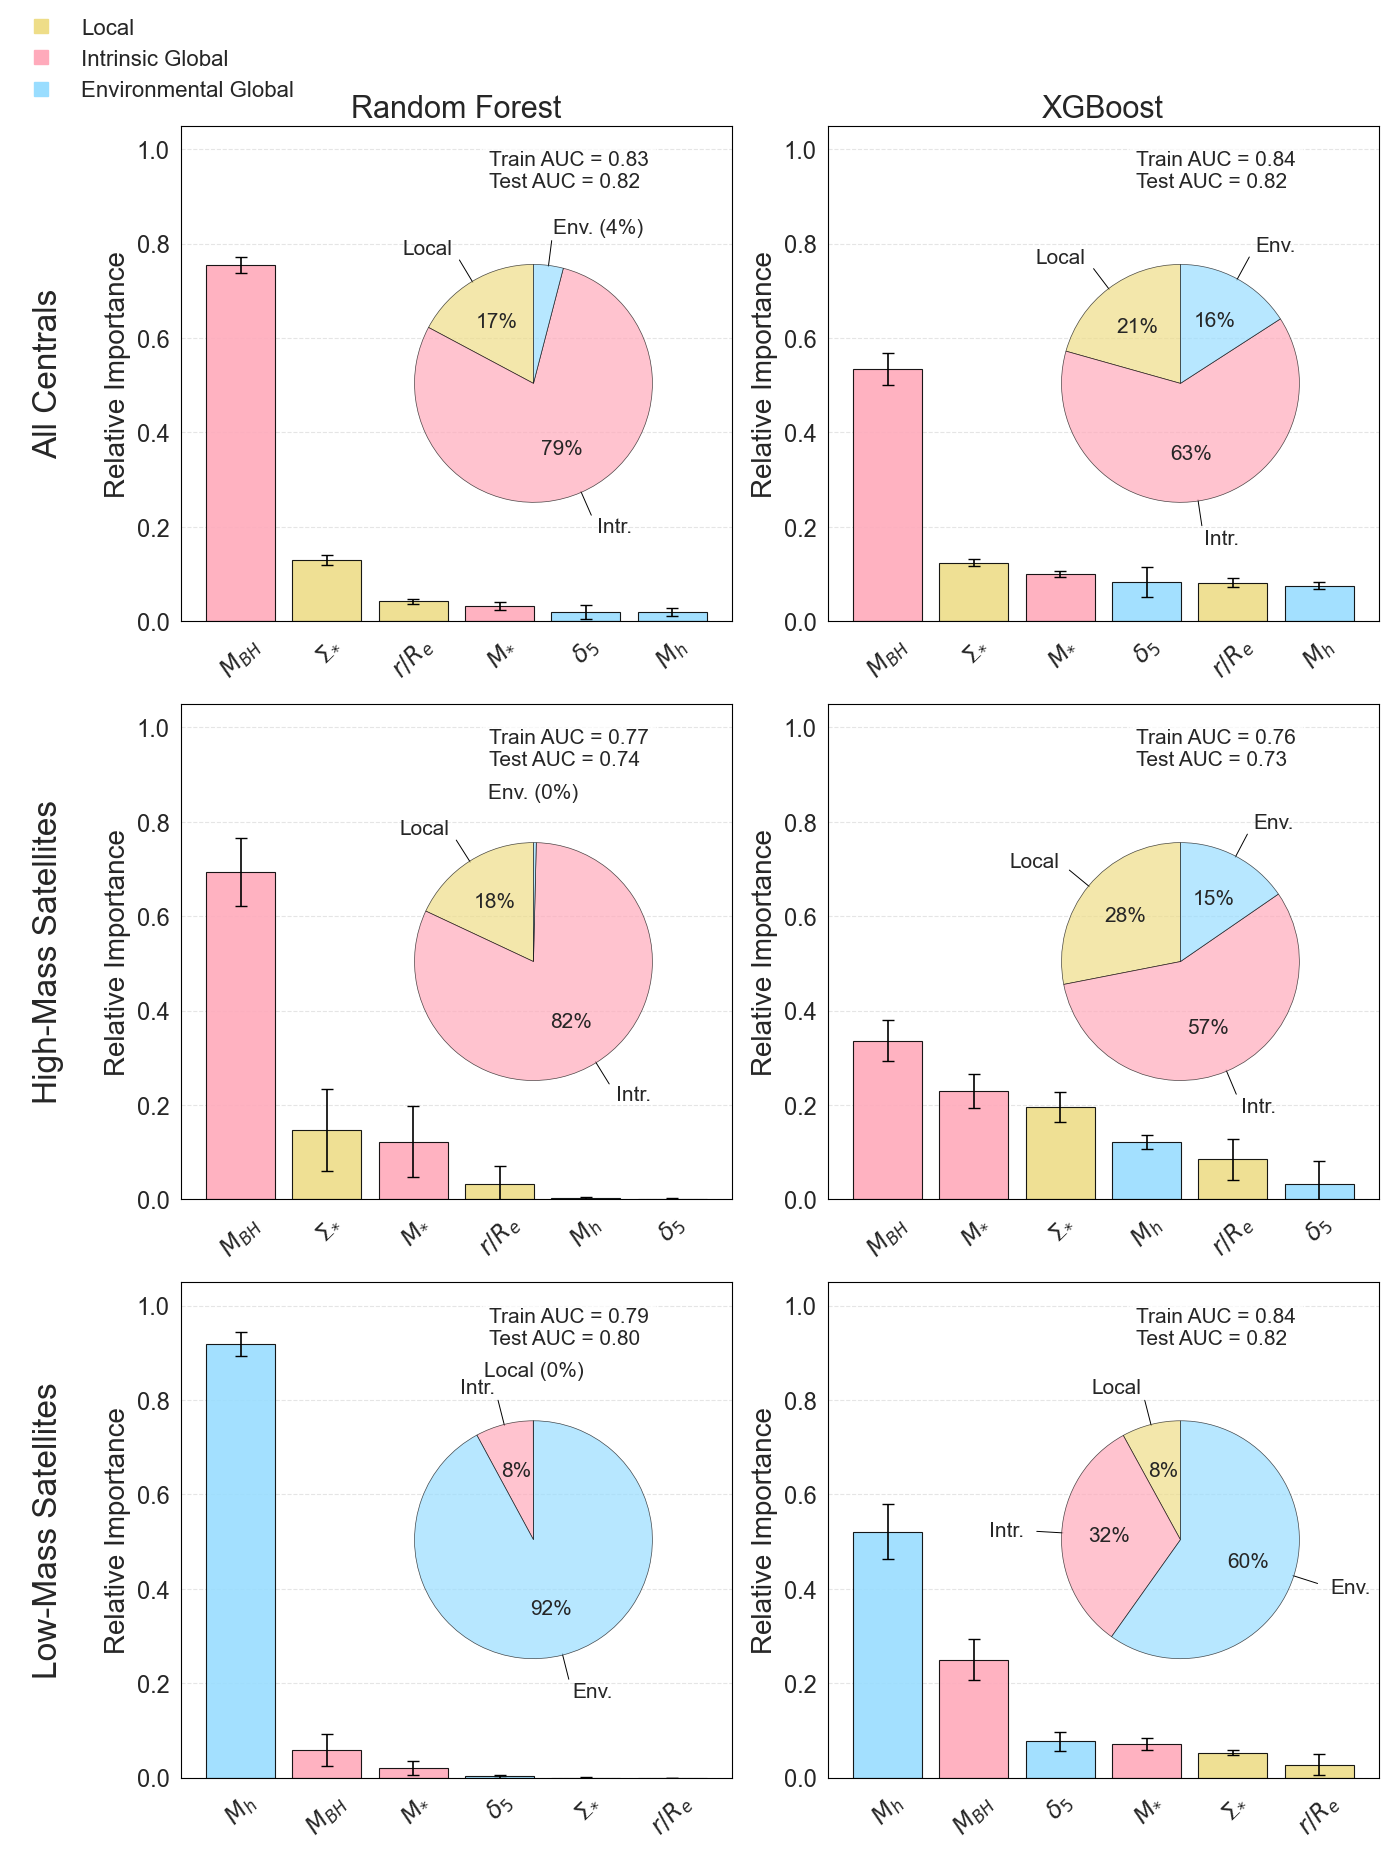

In [13]:
# Row-major order: rows = galaxy sample, columns = model
# [AC-RF, AC-XG, HMS-RF, HMS-XG, LMS-RF, LMS-XG]
clf_imps = [
    pd.read_csv(f"{RF_CLF}/all_centrals_rf_quenching_halosplit.csv"),
    pd.read_csv(f"{XG_CLF}/all_centrals_xg_quenching_halosplit.csv"),
    pd.read_csv(f"{RF_CLF}/hms_rf_quenching_halosplit.csv"),
    pd.read_csv(f"{XG_CLF}/hms_xg_quenching_halosplit.csv"),
    pd.read_csv(f"{RF_CLF}/lms_rf_quenching_halosplit.csv"),
    pd.read_csv(f"{XG_CLF}/lms_xg_quenching_halosplit.csv"),
]
clf_metrics = [
    pd.read_csv(f"{RF_CLF}/all_centrals_rf_quenching_auc_halosplit.csv"),
    pd.read_csv(f"{XG_CLF}/all_centrals_xg_quenching_auc_halosplit.csv"),
    pd.read_csv(f"{RF_CLF}/hms_rf_quenching_auc_halosplit.csv"),
    pd.read_csv(f"{XG_CLF}/hms_xg_quenching_auc_halosplit.csv"),
    pd.read_csv(f"{RF_CLF}/lms_rf_quenching_auc_halosplit.csv"),
    pd.read_csv(f"{XG_CLF}/lms_xg_quenching_auc_halosplit.csv"),
]

six_panel(clf_imps, clf_metrics, col_titles, row_titles, metric_type='AUC',
          save_path='../pubplots/classification_six_panel_halosplit.pdf',
          mid_threshold=5, under_threshold=2)

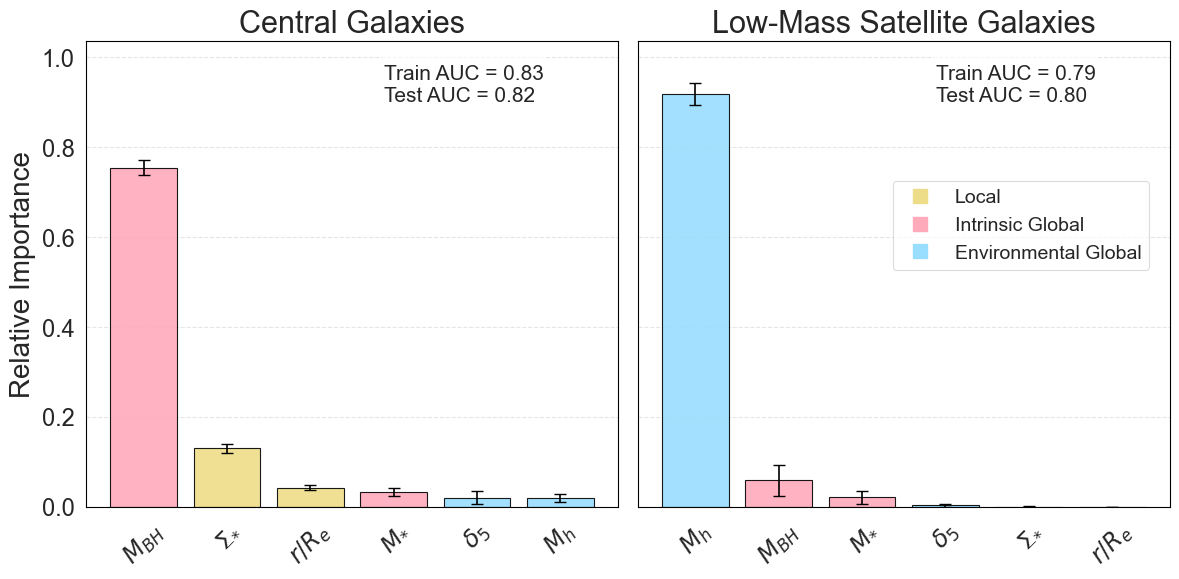

In [14]:
# Two-panel version: Random Forest classification only, Centrals vs Low-Mass
# Satellites. No pie charts; train/test AUC retained; color legend lives in
# the right-hand panel.
def two_panel_rf_classification(imps, metrics, panel_titles, save_path=None, figsize=(12, 6)):
    plt.rcParams.update({
        "text.usetex": False,
        "font.family": "serif",
        "font.serif": ["Times New Roman"],
    })
    sns.set_style("whitegrid")
    sns.set_context("paper", font_scale=1.4)

    max_imp = max((df['Mean Importance'] + df['Std Dev']).max() for df in imps) * 1.1

    fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=True)

    for i, (df, mdf, ax) in enumerate(zip(imps, metrics, axes)):
        df = df.sort_values('Mean Importance', ascending=False).copy()
        df['orig_feature'] = df['Feature']
        df['Feature'] = df['Feature'].map(lambda x: latex_labels.get(x, x))

        colors = [local_color if feat in local_features
                  else intrinsic_global_color if feat in intrinsic_global_features
                  else environmental_global_color for feat in df['orig_feature']]
        ax.bar(
            df['Feature'], df['Mean Importance'], yerr=df['Std Dev'],
            capsize=4, color=colors, edgecolor='black', linewidth=0.8, alpha=0.9
        )

        for spine in ax.spines.values():
            spine.set_edgecolor('black')
            spine.set_linewidth(0.8)

        ax.set_title(panel_titles[i], fontsize=22)
        ax.set_ylim(0, max_imp)
        ax.grid(axis='y', linestyle='--', alpha=0.5)
        ax.grid(False, axis='x')
        ax.tick_params(axis='x', labelrotation=45, labelsize=17)
        ax.tick_params(axis='y', labelsize=17)
        if i == 0:
            ax.set_ylabel(r'Relative Importance', fontsize=20)

        # Train/test AUC annotation
        mdf = mdf.copy()
        mdf.columns = mdf.columns.str.strip()
        train = mdf['Train AUC'].iloc[0]
        test = mdf['Test AUC'].iloc[0]
        textstr = f"Train AUC = {train:.2f}\nTest AUC = {test:.2f}"
        ax.text(0.56, 0.95, textstr, transform=ax.transAxes,
                fontsize=15, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

    # Color legend, placed inside the right-hand panel below the AUC box
    handles = [
        plt.Line2D([0], [0], marker='s', color=local_color, lw=0, markersize=10, label='Local'),
        plt.Line2D([0], [0], marker='s', color=intrinsic_global_color, lw=0, markersize=10, label='Intrinsic Global'),
        plt.Line2D([0], [0], marker='s', color=environmental_global_color, lw=0, markersize=10, label='Environmental Global'),
    ]
    axes[1].legend(handles=handles, loc='upper right', bbox_to_anchor=(0.98, 0.72),
                   frameon=True, framealpha=0.7, fontsize=14)

    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()


two_panel_rf_classification(
    imps=[clf_imps[0], clf_imps[4]],
    metrics=[clf_metrics[0], clf_metrics[4]],
    panel_titles=['Central Galaxies', 'Low-Mass Satellite Galaxies'],
    save_path='../pubplots/rf_classification_two_panel_halosplit.pdf',
)

## Regression (SFR)

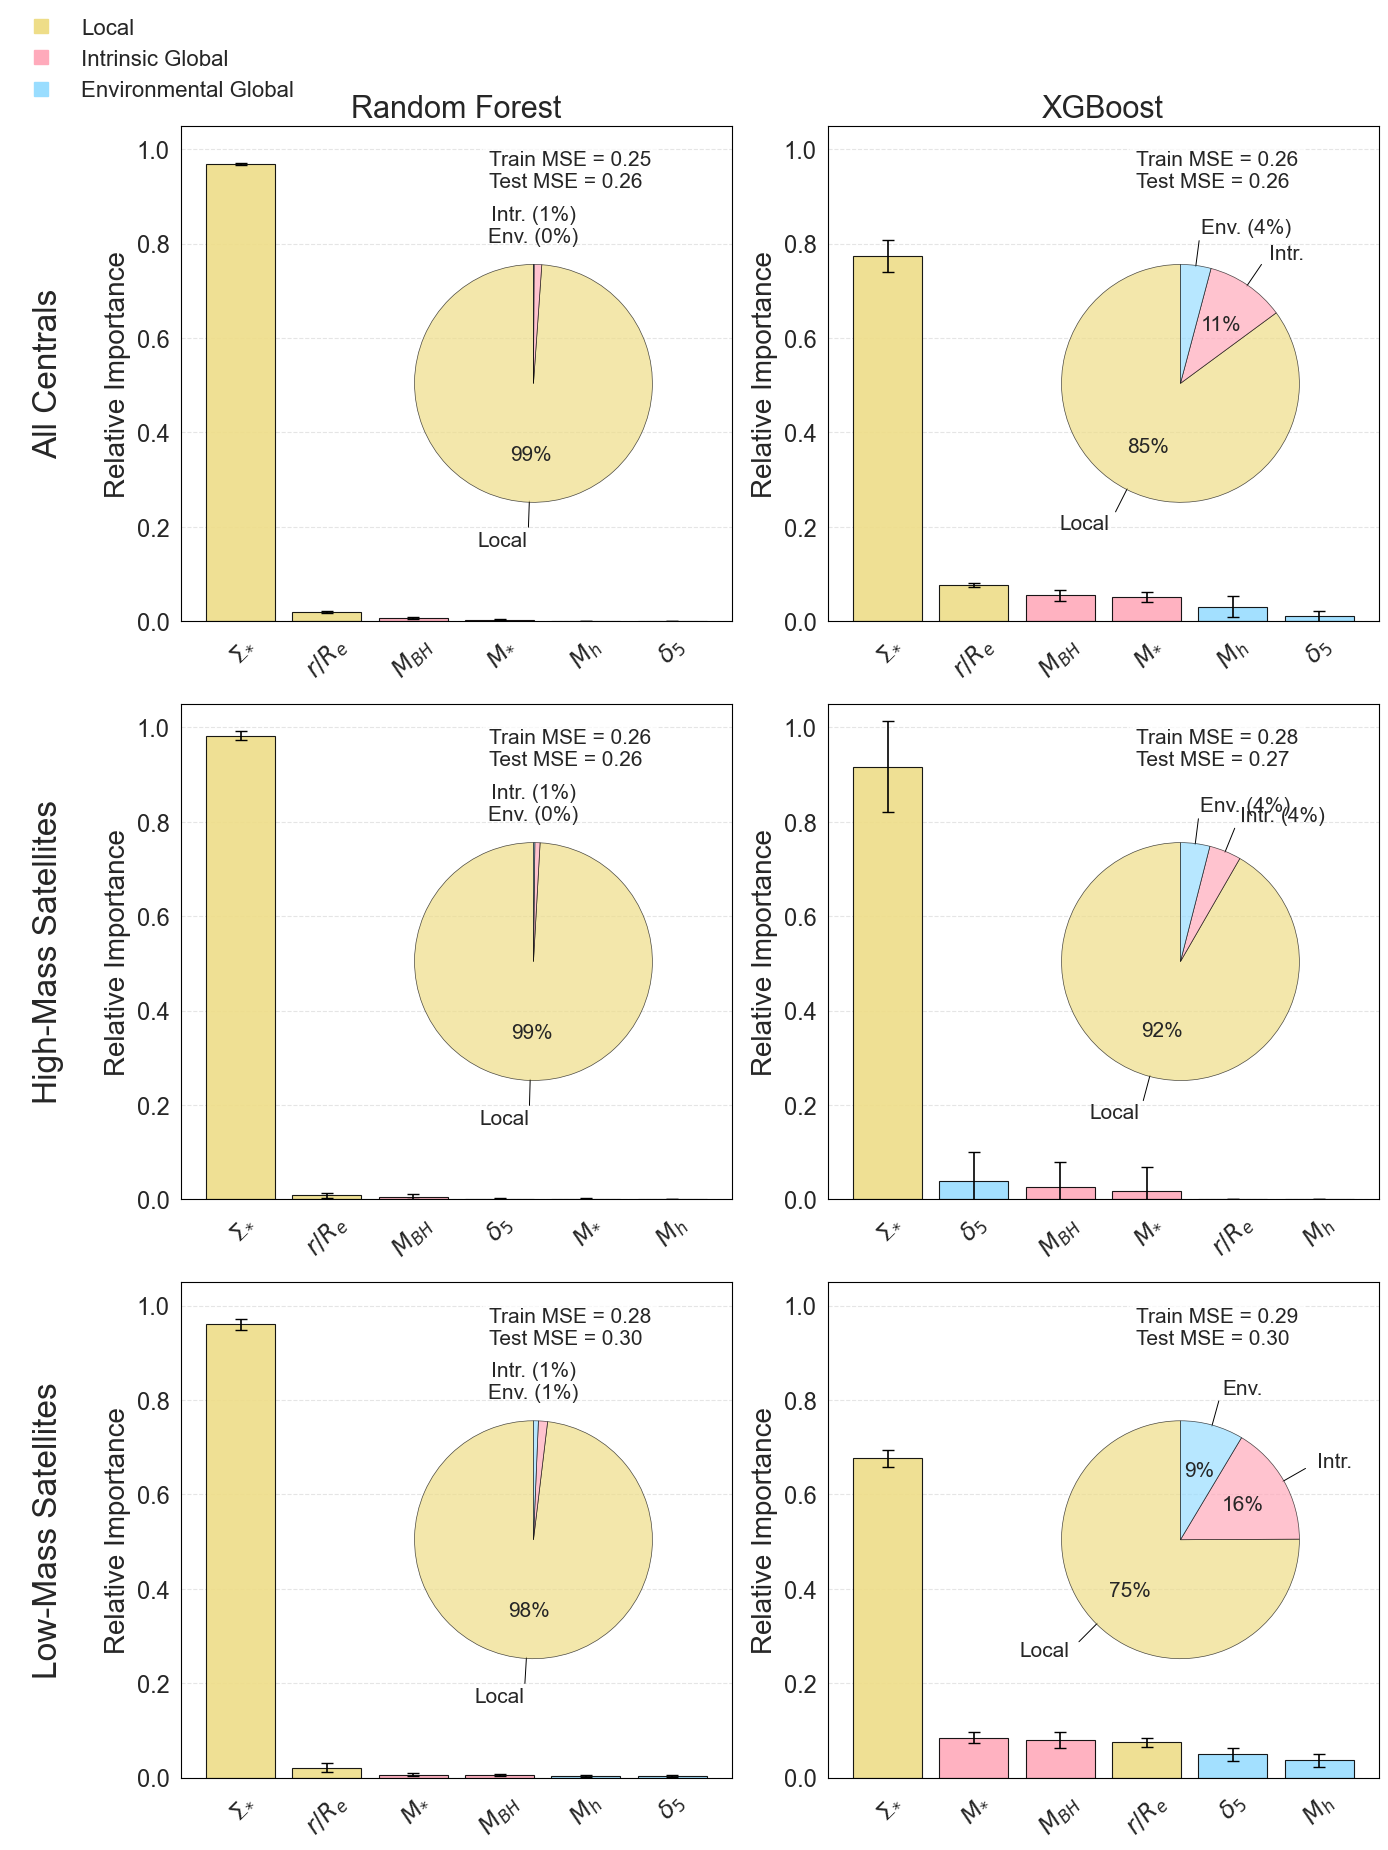

In [15]:
# Row-major order: rows = galaxy sample, columns = model
# [AC-RF, AC-XG, HMS-RF, HMS-XG, LMS-RF, LMS-XG]
reg_imps = [
    pd.read_csv(f"{RF_REG}/all_centrals_rf_reg_halosplit.csv"),
    pd.read_csv(f"{XG_REG}/all_centrals_xg_reg_halosplit.csv"),
    pd.read_csv(f"{RF_REG}/hms_rf_reg_halosplit.csv"),
    pd.read_csv(f"{XG_REG}/hms_xg_reg_halosplit.csv"),
    pd.read_csv(f"{RF_REG}/lms_rf_reg_halosplit.csv"),
    pd.read_csv(f"{XG_REG}/lms_xg_reg_halosplit.csv"),
]
reg_metrics = [
    pd.read_csv(f"{RF_REG}/all_centrals_rf_reg_mse_halosplit.csv"),
    pd.read_csv(f"{XG_REG}/all_centrals_xg_reg_mse_halosplit.csv"),
    pd.read_csv(f"{RF_REG}/hms_rf_reg_mse_halosplit.csv"),
    pd.read_csv(f"{XG_REG}/hms_xg_reg_mse_halosplit.csv"),
    pd.read_csv(f"{RF_REG}/lms_rf_reg_mse_halosplit.csv"),
    pd.read_csv(f"{XG_REG}/lms_xg_reg_mse_halosplit.csv"),
]

six_panel(reg_imps, reg_metrics, col_titles, row_titles, metric_type='MSE',
          save_path='../pubplots/regression_six_panel_halosplit.pdf',
          mid_threshold=7, under_threshold=2)

## Regression ($\Delta \Sigma_{\rm SFMS}$)

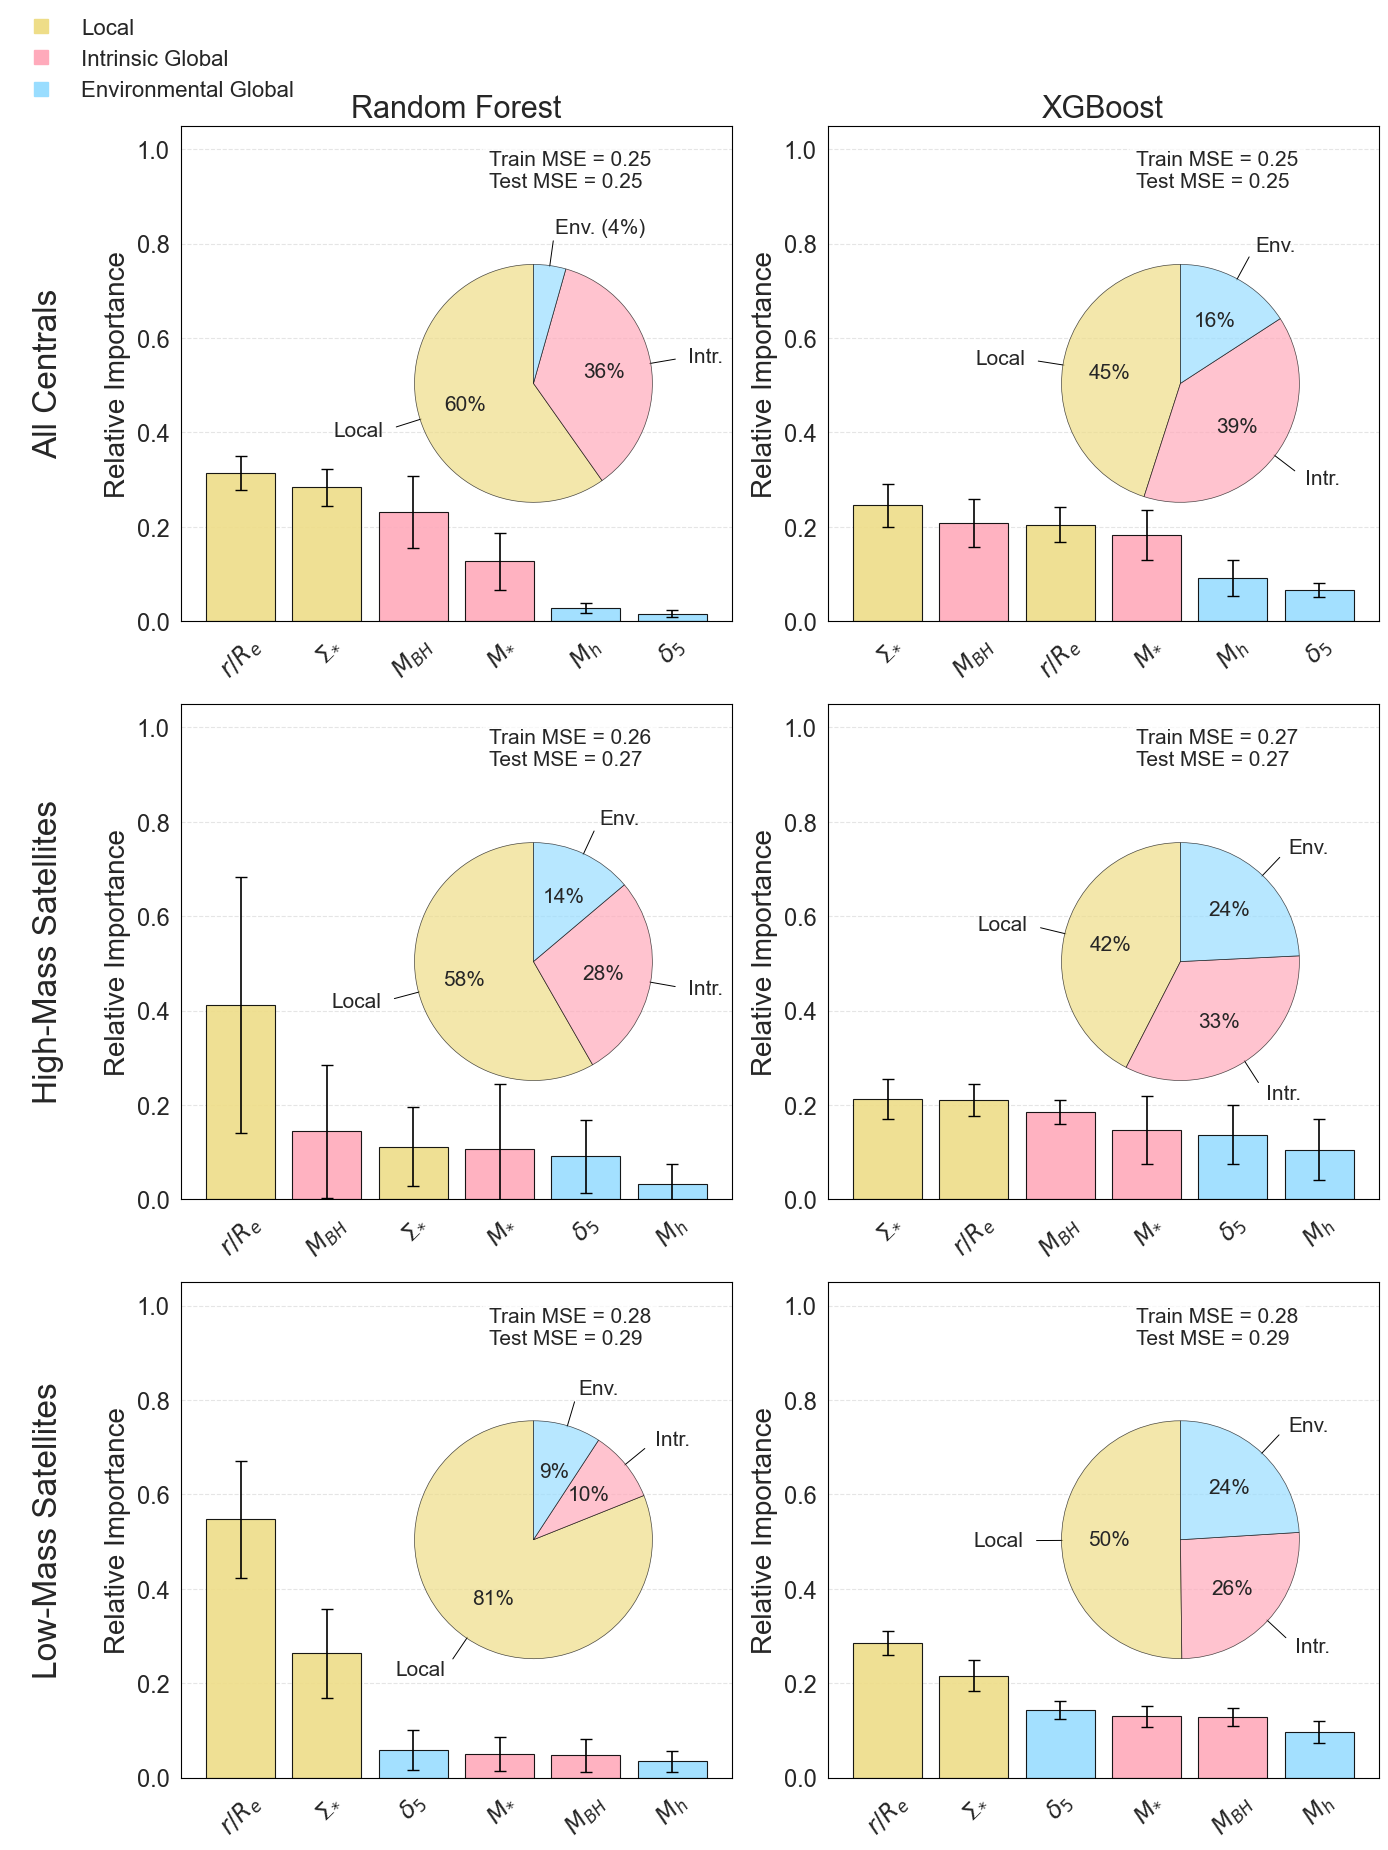

In [16]:
RF_DSS = "../regression_delsigsfr/rf_regression_annuli/rf_regression_outputs"
XG_DSS = "../regression_delsigsfr/xg_regression_annuli/xg_regression_outputs"

# Row-major order: rows = galaxy sample, columns = model
# [AC-RF, AC-XG, HMS-RF, HMS-XG, LMS-RF, LMS-XG]
dss_imps = [
    pd.read_csv(f"{RF_DSS}/all_centrals_rf_reg_halosplit.csv"),
    pd.read_csv(f"{XG_DSS}/all_centrals_xg_reg_halosplit.csv"),
    pd.read_csv(f"{RF_DSS}/hms_rf_reg_halosplit.csv"),
    pd.read_csv(f"{XG_DSS}/hms_xg_reg_halosplit.csv"),
    pd.read_csv(f"{RF_DSS}/lms_rf_reg_halosplit.csv"),
    pd.read_csv(f"{XG_DSS}/lms_xg_reg_halosplit.csv"),
]
dss_metrics = [
    pd.read_csv(f"{RF_DSS}/all_centrals_rf_reg_mse_halosplit.csv"),
    pd.read_csv(f"{XG_DSS}/all_centrals_xg_reg_mse_halosplit.csv"),
    pd.read_csv(f"{RF_DSS}/hms_rf_reg_mse_halosplit.csv"),
    pd.read_csv(f"{XG_DSS}/hms_xg_reg_mse_halosplit.csv"),
    pd.read_csv(f"{RF_DSS}/lms_rf_reg_mse_halosplit.csv"),
    pd.read_csv(f"{XG_DSS}/lms_xg_reg_mse_halosplit.csv"),
]

six_panel(dss_imps, dss_metrics, col_titles, row_titles, metric_type='MSE',
          save_path='../pubplots/regression_delsigsfr_six_panel_halosplit.pdf',
          mid_threshold=7, under_threshold=2)
